<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 03: Randomized blocks and factorial designs

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapters 4 and 5.
Problem numbers follow the 8th edition.

## Learning goals

* Analyse a randomized complete block design (RCBD) in `statsmodels` and see what happens when the blocks are ignored.
* Quantify the benefit of blocking with the relative efficiency of the RCBD.
* Compare treatment means with Fisher's LSD and Tukey's HSD using the error mean square of the *correct* model.
* Fit and interpret a two-factor factorial model with interaction: interaction plots, ANOVA, simple effects, residual analysis.
* Test for nonadditivity when there is only one observation per cell (Tukey's one-degree-of-freedom test).
* Compute the power of the ANOVA $F$-test from the noncentral $F$ distribution and choose the number of blocks or replicates.
* Model a quantitative factor with response curves and surfaces; analyse a three-factor factorial and a factorial run in blocks.

## Setup

Run this cell first. Besides the standard imports it defines three small helper functions used throughout the notebook:

* `tukey_from_model()` - Tukey's HSD with $MS_E$ and $df_E$ taken from a fitted model with blocks or several factors.
  (`pairwise_tukeyhsd()` from `statsmodels` always fits a one-way model, so it uses the wrong error mean square in these designs.)
* `tukey_nonadditivity()` - Tukey's one-degree-of-freedom test for nonadditivity (one observation per cell).
* `anova_power()` - power of the ANOVA $F$-test for a given noncentrality parameter $\lambda$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.factorplots import interaction_plot
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from pathlib import Path
from IPython.display import display

DATA_DIR = next((p for p in [Path("../data"), Path("data"), Path("01NAEX/data")]
                 if (p / "Chapter5_Pr06.csv").is_file()), None)
URL = (str(DATA_DIR) + "/" if DATA_DIR is not None else
       "https://raw.githubusercontent.com/francji1/01NAEX/main/data/")


def tukey_from_model(model, data, factor, response, alpha=0.05):
    """Tukey's HSD for the levels of `factor`, using MS_E and df_E of a fitted model.

    Balanced data are assumed (the same number of observations at every level of `factor`).
    """
    mse, dfe = model.mse_resid, model.df_resid
    means = data.groupby(factor, observed=True)[response].mean()
    n = data.groupby(factor, observed=True)[response].count().iloc[0]
    k = len(means)
    se = np.sqrt(mse / n)
    hsd = stats.studentized_range.ppf(1 - alpha, k, dfe) * se
    rows = []
    levels = list(means.index)
    for i in range(k):
        for j in range(i + 1, k):
            diff = means.iloc[j] - means.iloc[i]
            rows.append({"pair": f"{levels[j]} - {levels[i]}", "diff": diff,
                         "lower": diff - hsd, "upper": diff + hsd,
                         "p_adj": stats.studentized_range.sf(abs(diff) / se, k, dfe),
                         "reject": abs(diff) > hsd})
    print(f"MS_E = {mse:.4g}, df_E = {dfe:.0f}, n per level = {n}, HSD = {hsd:.4g}")
    return pd.DataFrame(rows)


def tukey_nonadditivity(data, response, row, col):
    """Tukey's one-degree-of-freedom test for nonadditivity in a two-way layout with one observation per cell.

    The covariate q = (row mean - grand mean) * (column mean - grand mean) is added to the additive model;
    its sequential sum of squares is SS_N (1 df) and the remaining residual is SS_Error.
    """
    d = data.copy()
    g = d[response].mean()
    d["q_nonadd"] = ((d.groupby(row)[response].transform("mean") - g)
                     * (d.groupby(col)[response].transform("mean") - g))
    fit = smf.ols(f"{response} ~ C({row}) + C({col}) + q_nonadd", data=d).fit()
    return sm.stats.anova_lm(fit, typ=1)


def anova_power(lam, df1, df2, alpha=0.05):
    """Power of the ANOVA F-test: P(F'(df1, df2, lam) > F_{1-alpha; df1, df2})."""
    return stats.ncf.sf(stats.f.ppf(1 - alpha, df1, df2), df1, df2, lam)

## 1. Lecture example: hardness testing experiment (RCBD)

Lecture 3 analysed the hardness testing experiment (Montgomery, Section 4.1, data from Problem 4.7). A machine measures hardness by
pressing a tip into a metal test coupon. Four types of tips are compared; the coupons may differ, so each of the four
coupons is used as a **block** and all four tips are tested on every coupon in random order. The response is the
Rockwell C-scale reading minus 40.

The data set is small, so we type it in.

In [2]:
y = [[9.3, 9.4, 9.6, 10.0],     # tip 1, coupons 1-4
     [9.4, 9.3, 9.8, 9.9],      # tip 2
     [9.2, 9.4, 9.5, 9.7],      # tip 3
     [9.7, 9.6, 10.0, 10.2]]    # tip 4
hard = pd.DataFrame([(t + 1, c + 1, y[t][c]) for t in range(4) for c in range(4)],
                    columns=["Tip", "Coupon", "y"])
hard.pivot(index="Tip", columns="Coupon", values="y")

Coupon,1,2,3,4
Tip,,,,
1,9.3,9.4,9.6,10.0
2,9.4,9.3,9.8,9.9
3,9.2,9.4,9.5,9.7
4,9.7,9.6,10.0,10.2


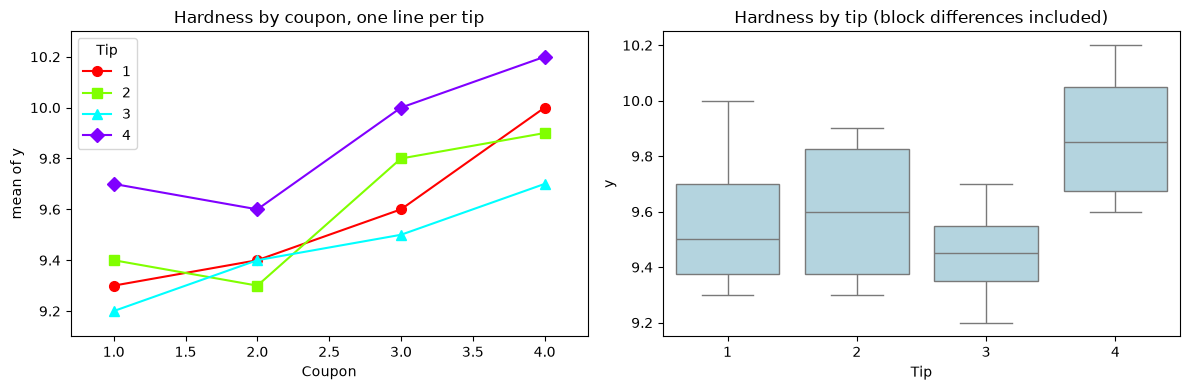

In [3]:
# Left: readings of each tip across the coupons (blocks); right: tips compared within coupons.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(hard["Coupon"], hard["Tip"], hard["y"], ax=axes[0], markers=["o", "s", "^", "D"], ms=7)
axes[0].set_title("Hardness by coupon, one line per tip")
sns.boxplot(data=hard, x="Tip", y="y", ax=axes[1], color="lightblue")
axes[1].set_title("Hardness by tip (block differences included)")
plt.tight_layout(); plt.show()

The lines in the left plot are roughly parallel: the coupons shift all readings up or down by a similar amount
(block effect) and tip 4 reads highest on every coupon. The boxplot on the right mixes the coupon-to-coupon variability into
the spread of each tip, which hides the tip effect.

### ANOVA of the RCBD and the same data analysed as a completely randomized design

In [4]:
rcbd = smf.ols("y ~ C(Tip) + C(Coupon)", data=hard).fit()
crd = smf.ols("y ~ C(Tip)", data=hard).fit()
print("RCBD: tips + coupons (blocks)")
display(sm.stats.anova_lm(rcbd, typ=2))
print("CRD: blocks ignored")
display(sm.stats.anova_lm(crd, typ=2))
print(f"MS_E RCBD = {rcbd.mse_resid:.5f}, MS_E CRD = {crd.mse_resid:.5f}, ratio = {crd.mse_resid / rcbd.mse_resid:.2f}")

RCBD: tips + coupons (blocks)


,sum_sq,df,F,PR(>F)
C(Tip),0.385,3.0,14.4375,0.000871
C(Coupon),0.825,3.0,30.9375,0.000045
Residual,0.080,9.0,NaN,NaN


CRD: blocks ignored


,sum_sq,df,F,PR(>F)
C(Tip),0.385,3.0,1.701657,0.219568
Residual,0.905,12.0,NaN,NaN


MS_E RCBD = 0.00889, MS_E CRD = 0.07542, ratio = 8.48


In the RCBD the tip effect is highly significant ($F_0 = 14.44$, $p = 0.0009$). Ignoring the blocks moves $SS_{Coupon}$ into
the error term, $MS_E$ grows about 8.5 times and the tip effect is no longer detected ($p = 0.22$).

### Relative efficiency of the RCBD

How many more observations would a completely randomized design need to estimate the tip means as precisely
(Montgomery, Supplemental Material S4.1)?

$$
R = \frac{(df_b+1)(df_r+3)}{(df_b+3)(df_r+1)}\,\frac{\hat\sigma_r^2}{\hat\sigma_b^2},\qquad
\hat\sigma_r^2 = \frac{(b-1)MS_{Blocks} + b(a-1)MS_E}{ab-1},\qquad \hat\sigma_b^2 = MS_E,
$$

with $df_b = (a-1)(b-1)$ and $df_r = a(b-1)$ the error degrees of freedom of the RCBD and of the CRD.

In [5]:
def relative_efficiency(model, block, a, b):
    """Relative efficiency of an RCBD with a treatments and b blocks with respect to a CRD."""
    tab = sm.stats.anova_lm(model, typ=2)
    ms_block = tab.loc[block, "sum_sq"] / tab.loc[block, "df"]
    mse = model.mse_resid
    sigma2_crd = ((b - 1) * ms_block + b * (a - 1) * mse) / (a * b - 1)
    df_b, df_r = (a - 1) * (b - 1), a * (b - 1)
    correction = (df_b + 1) * (df_r + 3) / ((df_b + 3) * (df_r + 1))
    return sigma2_crd / mse, correction * sigma2_crd / mse

ratio, R = relative_efficiency(rcbd, "C(Coupon)", a=4, b=4)
print(f"variance ratio = {ratio:.2f}, relative efficiency R = {R:.2f}")

variance ratio = 6.99, relative efficiency R = 6.72


A completely randomized design would need about 6.7 times as many runs per tip to reach the same precision.

### Which tips differ?

Fisher's LSD and Tukey's HSD must use $MS_E$ and $df_E$ of the RCBD model. For comparison, the last output shows what
`pairwise_tukeyhsd()` reports: it fits a one-way model (blocks ignored) and finds no difference at all.

In [6]:
mse, dfe = rcbd.mse_resid, rcbd.df_resid
b = hard["Coupon"].nunique()
lsd = stats.t.ppf(0.975, dfe) * np.sqrt(2 * mse / b)
print("Tip means:", hard.groupby("Tip")["y"].mean().round(3).to_dict())
print(f"Fisher LSD = {lsd:.4f}")

tukey_tips = tukey_from_model(rcbd, hard, "Tip", "y")
tukey_tips["|diff| > LSD"] = tukey_tips["diff"].abs() > lsd
display(tukey_tips.round(4))

print("WRONG for an RCBD - pairwise_tukeyhsd() ignores the blocks:")
print(pairwise_tukeyhsd(hard["y"], hard["Tip"]))

Tip means: {1: 9.575, 2: 9.6, 3: 9.45, 4: 9.875}
Fisher LSD = 0.1508


MS_E = 0.008889, df_E = 9, n per level = 4, HSD = 0.2081


,pair,diff,lower,upper,p_adj,reject,|diff| > LSD
0,2 - 1,0.025,-0.1831,0.2331,0.9809,False,False
1,3 - 1,-0.125,-0.3331,0.0831,0.3028,False,False
2,4 - 1,0.300,0.0919,0.5081,0.0067,True,True
3,3 - 2,-0.150,-0.3581,0.0581,0.1816,False,False
4,4 - 2,0.275,0.0669,0.4831,0.0113,True,True
5,4 - 3,0.425,0.2169,0.6331,0.0006,True,True


WRONG for an RCBD - pairwise_tukeyhsd() ignores the blocks:


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2    0.025 0.9992 -0.5515 0.6015  False
     1      3   -0.125 0.9157 -0.7015 0.4515  False
     1      4      0.3 0.4431 -0.2765 0.8765  False
     2      3    -0.15 0.8653 -0.7265 0.4265  False
     2      4    0.275 0.5135 -0.3015 0.8515  False
     3      4    0.425 0.1816 -0.1515 1.0015  False
---------------------------------------------------

Tip 4 gives higher readings than tips 1, 2 and 3; tips 1, 2 and 3 do not differ (the comparison 3 - 2 is borderline for LSD).

### Model adequacy

Residuals versus fitted values, normal probability plot and residuals versus both factors. With one observation per cell
we cannot fit the tip $\times$ coupon interaction, but Tukey's one-degree-of-freedom test checks the additivity assumption.

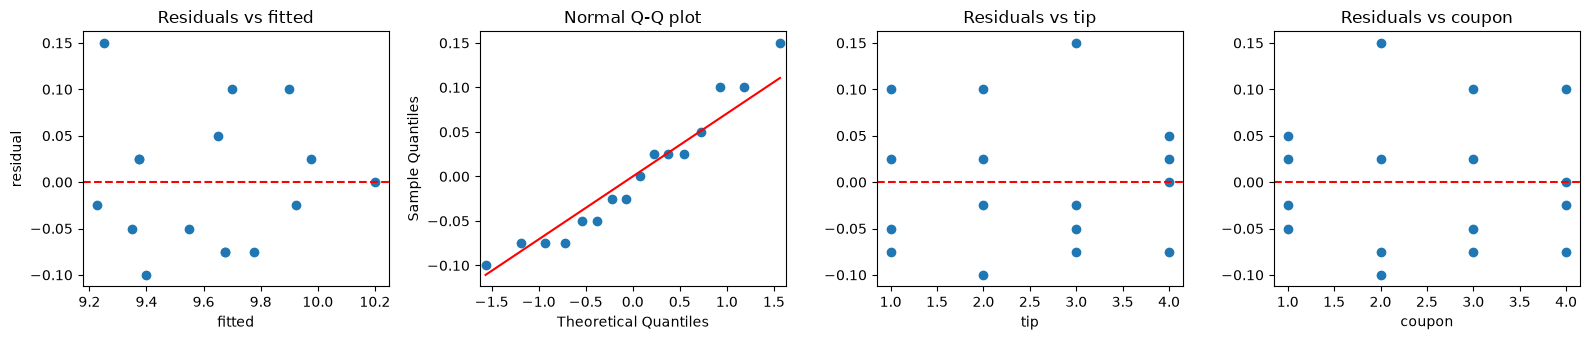

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.93957499360615), pvalue=np.float64(0.34384049244113535))

Tukey's test for nonadditivity (row q_nonadd):


,df,sum_sq,mean_sq,F,PR(>F)
C(Tip),3.0,0.38500,0.12833,13.52306,0.00169
C(Coupon),3.0,0.82500,0.27500,28.97798,0.00012
q_nonadd,1.0,0.00408,0.00408,0.42996,0.53041
Residual,8.0,0.07592,0.00949,NaN,NaN


In [7]:
res, fit = rcbd.resid, rcbd.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(hard["Tip"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="tip", title="Residuals vs tip")
axes[3].scatter(hard["Coupon"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="coupon", title="Residuals vs coupon")
plt.tight_layout(); plt.show()

print("Shapiro-Wilk on residuals:", stats.shapiro(res))
print("\nTukey's test for nonadditivity (row q_nonadd):")
display(tukey_nonadditivity(hard, "y", "Tip", "Coupon").round(5))

No pattern in the residuals, normality is acceptable and there is no evidence of nonadditivity ($p = 0.53$).

### How many blocks?

We want to detect a true maximum difference of $D = 0.4$ between two tip means with high probability, with
$\sigma = 0.1$. For the least favourable configuration (two means $D$ apart, the others in the middle)
$\lambda = bD^2/(2\sigma^2)$, $\Phi^2 = \lambda/a$, and $F_0 \sim F_{a-1,(a-1)(b-1)}(\lambda)$ under $H_1$.

In [8]:
a, D, sigma = 4, 0.4, 0.1
rows = []
for b in range(3, 9):
    lam = b * D**2 / (2 * sigma**2)
    df1, df2 = a - 1, (a - 1) * (b - 1)
    rows.append({"blocks b": b, "Phi": np.sqrt(lam / a), "lambda": lam, "df2": df2,
                 "power": anova_power(lam, df1, df2)})
display(pd.DataFrame(rows).round(4))

,blocks b,Phi,lambda,df2,power
0,3,2.4495,24.0,6,0.8461
1,4,2.8284,32.0,9,0.9757
2,5,3.1623,40.0,12,0.9972
3,6,3.4641,48.0,15,0.9997
4,7,3.7417,56.0,18,1.0000
5,8,4.0000,64.0,21,1.0000


## 2. Lecture example: battery life (two-factor factorial)

Montgomery, Example 5.1: the effective life (hours) of a battery for three plate materials and three temperatures
(15, 70, 125 $^\circ$F), $n = 4$ replicates, all 36 runs in random order. Questions: what effects do material and
temperature have on life, and is there a material that gives uniformly long life regardless of temperature?

In [9]:
bat = pd.read_csv(URL + "battery.txt", sep=r"\s+")
print(bat.shape)
display(bat.pivot_table(index="Material", columns="Temperature", values="Life", aggfunc="mean"))
display(bat.pivot_table(index="Material", columns="Temperature", values="Life", aggfunc="std").round(2))

(36, 3)


Temperature,15,70,125
Material,,,
1,134.75,57.25,57.5
2,155.75,119.75,49.5
3,144.00,145.75,85.5


Temperature,15,70,125
Material,,,
1,45.35,23.60,26.85
2,25.62,12.66,19.26
3,25.97,22.54,19.28


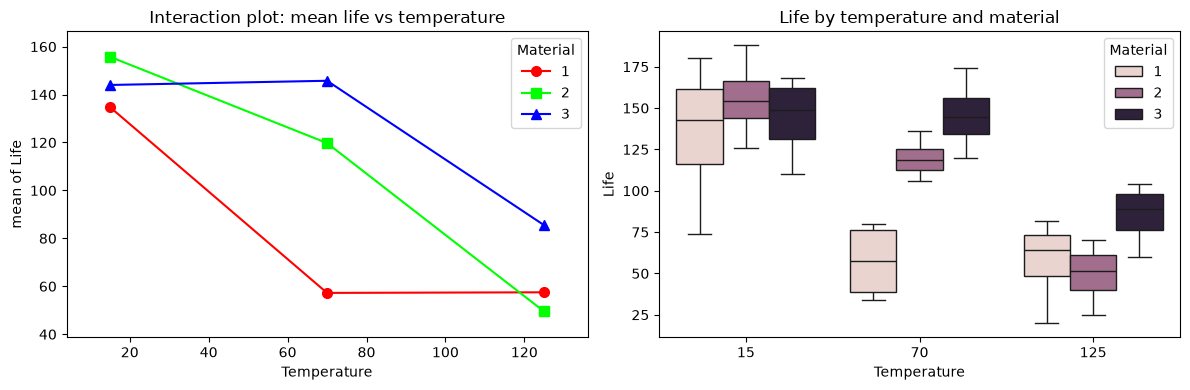

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
interaction_plot(bat["Temperature"], bat["Material"], bat["Life"], ax=axes[0], markers=["o", "s", "^"], ms=7)
axes[0].set_title("Interaction plot: mean life vs temperature")
sns.boxplot(data=bat, x="Temperature", y="Life", hue="Material", ax=axes[1])
axes[1].set_title("Life by temperature and material")
plt.tight_layout(); plt.show()

The lines are not parallel: material 1 loses most of its life already at 70 $^\circ$F, materials 2 and 3 only at 125 $^\circ$F.

### ANOVA with and without interaction

In [11]:
full = smf.ols("Life ~ C(Material) * C(Temperature)", data=bat).fit()
add = smf.ols("Life ~ C(Material) + C(Temperature)", data=bat).fit()
display(sm.stats.anova_lm(full, typ=2))
display(sm.stats.anova_lm(add, typ=2))
print("F-test for the interaction (additive vs full model):")
display(sm.stats.anova_lm(add, full))

,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,7.911372,1.976083e-03
C(Temperature),39118.722222,2.0,28.967692,1.908596e-07
C(Material):C(Temperature),9613.777778,4.0,3.559535,1.861117e-02
Residual,18230.750000,27.0,NaN,NaN


,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,5.947226,0.006515
C(Temperature),39118.722222,2.0,21.775919,0.000001
Residual,27844.527778,31.0,NaN,NaN


F-test for the interaction (additive vs full model):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,31.0,27844.527778,0.0,NaN,NaN,NaN
1,27.0,18230.750000,4.0,9613.777778,3.559535,0.018611


### Model adequacy

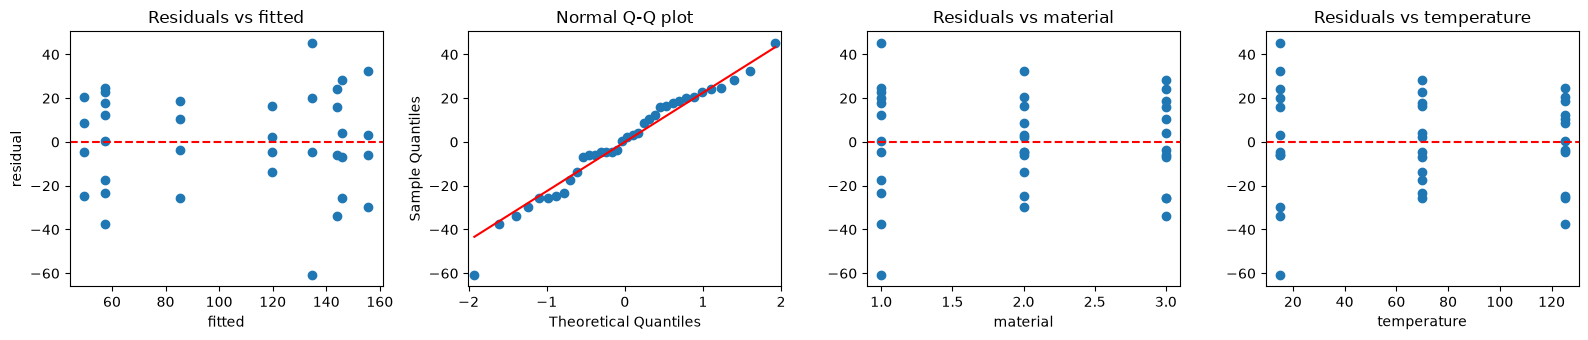

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9760570230871318), pvalue=np.float64(0.6117266783415353))
Levene (Brown-Forsythe) across the 9 cells: LeveneResult(statistic=np.float64(0.7995970449966421), pvalue=np.float64(0.6081330500874305))


In [12]:
res, fit = full.resid, full.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(bat["Material"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="material", title="Residuals vs material")
axes[3].scatter(bat["Temperature"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="temperature", title="Residuals vs temperature")
plt.tight_layout(); plt.show()

cells_ = [g["Life"].to_numpy(dtype=float) for _, g in bat.groupby(["Material", "Temperature"])]
print("Shapiro-Wilk on residuals:", stats.shapiro(res))
print("Levene (Brown-Forsythe) across the 9 cells:", stats.levene(*cells_))

The residual plots show slightly larger spread for material 1 at 15 $^\circ$F (one low observation, 74 h), but no serious
violation of the assumptions.

### Comparisons of means

Tukey's HSD for the main effects uses $MS_E = 675.2$ with 27 df from the full model. Because the interaction is significant,
the main-effect comparisons average over very different situations; the **simple effects** (materials compared at a fixed
temperature, $n = 4$ per cell, pooled $MS_E$) answer the practical question.

In [13]:
display(tukey_from_model(full, bat, "Material", "Life").round(4))
display(tukey_from_model(full, bat, "Temperature", "Life").round(4))

MS_E = 675.2, df_E = 27, n per level = 12, HSD = 26.3


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,25.1667,-1.1357,51.4690,0.0628,False
1,3 - 1,41.9167,15.6143,68.2190,0.0014,True
2,3 - 2,16.7500,-9.5523,43.0523,0.2718,False


MS_E = 675.2, df_E = 27, n per level = 12, HSD = 26.3


,pair,diff,lower,upper,p_adj,reject
0,70 - 15,-37.2500,-63.5523,-10.9477,0.0044,True
1,125 - 15,-80.6667,-106.9690,-54.3643,0.0000,True
2,125 - 70,-43.4167,-69.7190,-17.1143,0.0010,True


In [14]:
mse, dfe = full.mse_resid, full.df_resid
T = stats.studentized_range.ppf(0.95, 3, dfe) * np.sqrt(mse / 4)
print(f"Critical difference for materials within one temperature: T = {T:.2f}")
rows = []
for temp, sub in bat.groupby("Temperature"):
    m = sub.groupby("Material")["Life"].mean()
    for i, j in [(1, 2), (1, 3), (2, 3)]:
        rows.append({"Temperature": temp, "pair": f"{j} - {i}", "diff": m[j] - m[i], "significant": abs(m[j] - m[i]) > T})
pd.DataFrame(rows).pivot(index="Temperature", columns="pair", values="diff")

Critical difference for materials within one temperature: T = 45.56


pair,2 - 1,3 - 1,3 - 2
Temperature,,,
15,21.0,9.25,-11.75
70,62.5,88.50,26.00
125,-8.0,28.00,36.00


The materials differ only at 70 $^\circ$F (materials 2 and 3 better than 1). Material 3 gives long life at all three temperatures,
so it is the most robust choice.

### Sample size

How many replicates are needed to detect a difference of $D = 40$ h between two material means with $\sigma = 25$ h?
For factor $A$: $\Phi^2 = nbD^2/(2a\sigma^2)$, $\lambda = a\Phi^2$, $\nu_1 = a-1$, $\nu_2 = ab(n-1)$.

In [15]:
a = b = 3
D, sigma = 40, 25
rows = []
for n in [2, 3, 4, 5]:
    lam = n * b * D**2 / (2 * sigma**2)
    rows.append({"n": n, "Phi": np.sqrt(lam / a), "lambda": lam, "df2": a * b * (n - 1),
                 "power": anova_power(lam, a - 1, a * b * (n - 1))})
display(pd.DataFrame(rows).round(3))

,n,Phi,lambda,df2,power
0,2,1.600,7.68,9,0.542
1,3,1.960,11.52,18,0.803
2,4,2.263,15.36,27,0.923
3,5,2.530,19.20,36,0.972


### Response curves

Temperature is quantitative. With three levels we can fit at most a quadratic in temperature; letting the linear and
quadratic terms interact with material decomposes $SS_{Temperature}$ and $SS_{Material:Temperature}$ into single-degree-of-freedom parts.

,df,sum_sq,mean_sq,F,PR(>F)
C(Material),2.0,10683.722222,5341.861111,7.911372,1.976083e-03
T,1.0,39042.666667,39042.666667,57.822745,3.525248e-08
C(Material):T,2.0,2315.083333,1157.541667,1.714336,1.991088e-01
I(T ** 2),1.0,76.055556,76.055556,0.112639,7.397530e-01
C(Material):I(T ** 2),2.0,7298.694444,3649.347222,5.404735,1.061214e-02
Residual,27.0,18230.750000,675.212963,NaN,NaN


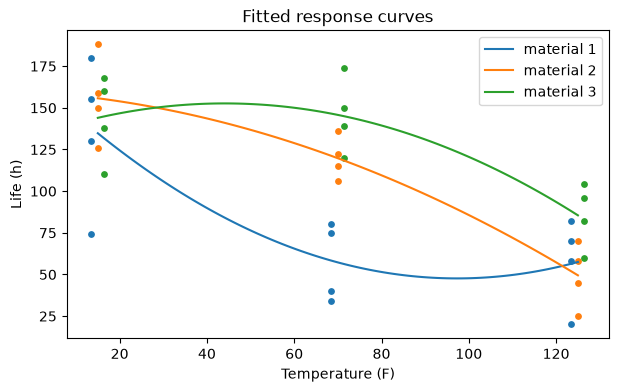

In [16]:
bat["T"] = bat["Temperature"].astype(float)
rc = smf.ols("Life ~ C(Material) + T + I(T**2) + C(Material):T + C(Material):I(T**2)", data=bat).fit()
display(sm.stats.anova_lm(rc, typ=1))

grid = np.linspace(15, 125, 100)
fig, ax = plt.subplots(figsize=(7, 4))
for mat, colour in zip([1, 2, 3], ["C0", "C1", "C2"]):
    pred = rc.predict(pd.DataFrame({"Material": mat, "T": grid}))
    ax.plot(grid, pred, color=colour, label=f"material {mat}")
    sub = bat[bat["Material"] == mat]
    ax.scatter(sub["T"] + (mat - 2) * 1.5, sub["Life"], color=colour, s=15)
ax.set(xlabel="Temperature (F)", ylabel="Life (h)", title="Fitted response curves")
ax.legend(); plt.show()

## 3. Lecture examples: blocking in a factorial, three factors, response surface

### Radar target detection (Example 5.6): a factorial run in blocks

Factors: filter type (2) and ground clutter (low, medium, high). Each of four operators runs all six combinations in
random order, so the operator is a **block**. The model is $y_{ijk} = \mu + \tau_i + \beta_j + (\tau\beta)_{ij} + \delta_k + \varepsilon_{ijk}$.

With operators as blocks


,sum_sq,df,F,PR(>F)
C(Operator),402.166667,3.0,12.089178,2.771485e-04
C(Filter),1066.666667,1.0,96.192385,6.446793e-08
C(Ground),335.583333,2.0,15.131513,2.527013e-04
C(Filter):C(Ground),77.083333,2.0,3.475701,5.750655e-02
Residual,166.333333,15.0,NaN,NaN


Blocks ignored


,sum_sq,df,F,PR(>F)
C(Filter),1066.666667,1.0,33.773087,0.000017
C(Ground),335.583333,2.0,5.312665,0.015371
C(Filter):C(Ground),77.083333,2.0,1.220317,0.318422
Residual,568.500000,18.0,NaN,NaN


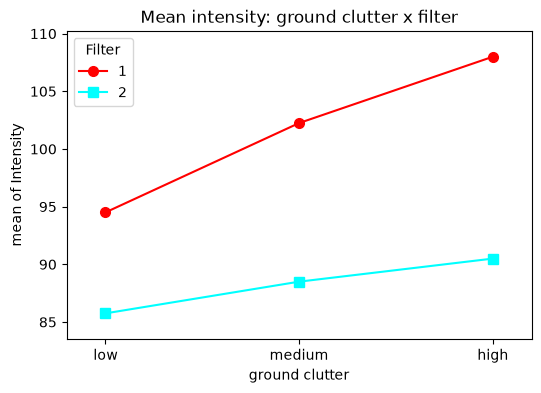

In [17]:
radar = pd.read_csv(URL + "intensity.txt", sep=r"\s+")
radar["Ground"] = pd.Categorical(radar["Ground"], categories=["low", "medium", "high"], ordered=True)
blk = smf.ols("Intensity ~ C(Operator) + C(Filter) * C(Ground)", data=radar).fit()
noblk = smf.ols("Intensity ~ C(Filter) * C(Ground)", data=radar).fit()
print("With operators as blocks"); display(sm.stats.anova_lm(blk, typ=2))
print("Blocks ignored"); display(sm.stats.anova_lm(noblk, typ=2))

fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(radar["Ground"].cat.codes, radar["Filter"], radar["Intensity"], ax=ax, markers=["o", "s"], ms=7)
ax.set_xticks([0, 1, 2], radar["Ground"].cat.categories)
ax.set(xlabel="ground clutter", title="Mean intensity: ground clutter x filter"); plt.show()

### Soft drink bottling (Example 5.3): three factors

Deviation from the target fill height for carbonation (10, 12, 14 %), operating pressure (25, 30 psi) and line speed
(200, 250 bottles/min), two replicates.

,sum_sq,df,F,PR(>F)
C(Carbonation),252.750000,2.0,178.411765,1.186249e-09
C(Pressure),45.375000,1.0,64.058824,3.742257e-06
C(Speed),22.041667,1.0,31.117647,1.202174e-04
C(Carbonation):C(Pressure),5.250000,2.0,3.705882,5.580812e-02
C(Carbonation):C(Speed),0.583333,2.0,0.411765,6.714939e-01
C(Pressure):C(Speed),1.041667,1.0,1.470588,2.485867e-01
C(Carbonation):C(Pressure):C(Speed),1.083333,2.0,0.764706,4.868711e-01
Residual,8.500000,12.0,NaN,NaN


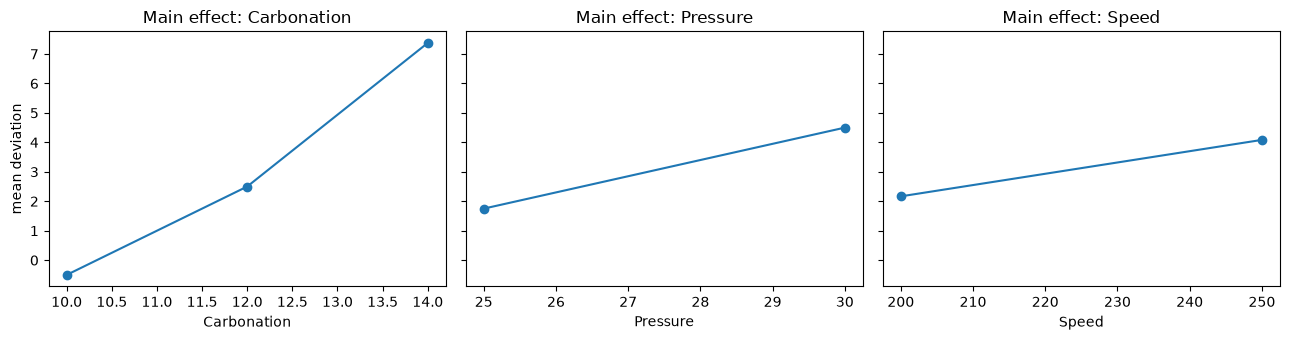

In [18]:
bot = pd.read_csv(URL + "bottling.txt", sep=r"\s+")
m3 = smf.ols("Deviation ~ C(Carbonation) * C(Pressure) * C(Speed)", data=bot).fit()
display(sm.stats.anova_lm(m3, typ=2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, factor in zip(axes, ["Carbonation", "Pressure", "Speed"]):
    bot.groupby(factor)["Deviation"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"Main effect: {factor}"); ax.set_ylabel("mean deviation")
plt.tight_layout(); plt.show()

### Tool life (Example 5.5): response surface for two quantitative factors

Cutting angle (15, 20, 25 degrees) and cutting speed (125, 150, 175 in/min), two replicates. The full model with linear and
quadratic terms in both factors and all their products has 9 parameters, one per cell mean.

,df,sum_sq,mean_sq,F,PR(>F)
Angle,1.0,8.333333,8.333333,5.769231,0.039772
I(Angle ** 2),1.0,16.000000,16.000000,11.076923,0.008824
Speed,1.0,21.333333,21.333333,14.769231,0.003948
I(Speed ** 2),1.0,4.000000,4.000000,2.769231,0.130451
Angle:Speed,1.0,8.000000,8.000000,5.538462,0.043065
Angle:I(Speed ** 2),1.0,42.666667,42.666667,29.538462,0.000414
I(Angle ** 2):Speed,1.0,2.666667,2.666667,1.846154,0.207306
I(Angle ** 2):I(Speed ** 2),1.0,8.000000,8.000000,5.538462,0.043065
Residual,9.0,13.000000,1.444444,NaN,NaN


Intercept                     -1068.000000
Angle                           136.300000
I(Angle ** 2)                    -4.080000
Speed                            14.480000
I(Speed ** 2)                    -0.049600
Angle:Speed                      -1.864000
Angle:I(Speed ** 2)               0.006400
I(Angle ** 2):Speed               0.056000
I(Angle ** 2):I(Speed ** 2)      -0.000192
dtype: float64


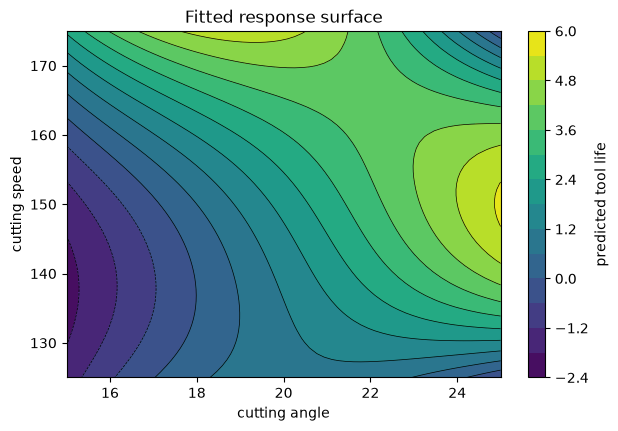

In [19]:
tool = pd.read_csv(URL + "toollife.txt", sep=r"\s+")
rs = smf.ols("Life ~ (Angle + I(Angle**2)) * (Speed + I(Speed**2))", data=tool).fit()
display(sm.stats.anova_lm(rs, typ=1))
print(rs.params.round(6))

A, S = np.meshgrid(np.linspace(15, 25, 60), np.linspace(125, 175, 60))
Z = rs.predict(pd.DataFrame({"Angle": A.ravel(), "Speed": S.ravel()})).to_numpy().reshape(A.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(A, S, Z, levels=12, cmap="viridis")
ax.contour(A, S, Z, levels=12, colors="k", linewidths=0.5)
fig.colorbar(cs, label="predicted tool life")
ax.set(xlabel="cutting angle", ylabel="cutting speed", title="Fitted response surface")
plt.show()

## In-class problems

Work in pairs; we discuss the results at the end of the class. For every test state the hypotheses, the test statistic,
the $p$-value and your decision.

### Problem 4.3 (with 4.16): chemical agents and cloth strength

A chemist wishes to test the effect of four chemical agents on the strength of a particular type of cloth. Because there might
be variability from one bolt to another, the chemist decides to use a randomized block design, with the bolts of cloth
considered as blocks. She selects five bolts and applies all four chemicals in random order to each bolt.
The resulting tensile strengths are:

| Chemical | Bolt 1 | Bolt 2 | Bolt 3 | Bolt 4 | Bolt 5 |
|---|---|---|---|---|---|
| 1 | 73 | 68 | 74 | 71 | 67 |
| 2 | 73 | 67 | 75 | 72 | 70 |
| 3 | 75 | 68 | 78 | 73 | 68 |
| 4 | 73 | 71 | 75 | 75 | 69 |

In [20]:
strength = [[73, 68, 74, 71, 67],
            [73, 67, 75, 72, 70],
            [75, 68, 78, 73, 68],
            [73, 71, 75, 75, 69]]
cloth = pd.DataFrame([(c + 1, b + 1, strength[c][b]) for c in range(4) for b in range(5)],
                     columns=["Chemical", "Bolt", "Strength"])
cloth.pivot(index="Chemical", columns="Bolt", values="Strength")

Bolt,1,2,3,4,5
Chemical,,,,,
1,73,68,74,71,67
2,73,67,75,72,70
3,75,68,78,73,68
4,73,71,75,75,69


**Question 1.** Plot the data (strength versus bolt, one line per chemical). What do you expect from the analysis?

In [21]:
# TODO: add your analysis here

**Question 2.** Analyse the data as an RCBD with $\alpha = 0.05$. Do the chemicals differ?

In [22]:
# TODO: add your analysis here

**Question 3.** (Problem 4.16) Assuming that chemical types and bolts are fixed, estimate the model parameters $\tau_i$ and $\beta_j$.

In [23]:
# TODO: add your analysis here

**Question 4.** Analyse the same data as if they came from a completely randomized design. Compare the error mean squares and compute the relative efficiency of the RCBD. Was blocking worthwhile?

In [24]:
# TODO: add your analysis here

**Question 5.** Analyse the residuals and perform Tukey's test for nonadditivity. Comment on model adequacy.

In [25]:
# TODO: add your analysis here

### Problems 5.4, 5.5 and 5.34: surface finish of a metal part

An engineer suspects that the surface finish of a metal part is influenced by the feed rate and the depth of cut. He selects
three feed rates (0.20, 0.25, 0.30 in/min) and four depths of cut (0.15, 0.18, 0.20, 0.25 in), and runs a factorial experiment
with three replicates.

In [26]:
finish = pd.read_csv(URL + "Chapter5_Pr02.csv", sep=";")
finish.columns = ["Depth", "Feed", "Finish"]
display(finish.pivot_table(index="Feed", columns="Depth", values="Finish", aggfunc=list))

Depth,0.15,0.18,0.20,0.25
Feed,,,,
0.20,"[74, 64, 60]","[79, 68, 73]","[82, 88, 92]","[99, 104, 96]"
0.25,"[92, 86, 88]","[98, 104, 88]","[99, 108, 95]","[104, 110, 99]"
0.30,"[99, 98, 102]","[104, 99, 95]","[108, 110, 99]","[114, 107, 111]"


**Question 1.** Draw an interaction plot. Then analyse the data and draw conclusions; report the $p$-values ($\alpha = 0.05$).

In [27]:
# TODO: add your analysis here

**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

In [28]:
# TODO: add your analysis here

**Question 3.** Obtain point estimates of the mean surface finish at each feed rate.

In [29]:
# TODO: add your analysis here

**Question 4.** (Problem 5.5) Compute a 95 percent confidence interval for the mean difference in response for feed rates of 0.20 and 0.25 in/min.

In [30]:
# TODO: add your analysis here

**Question 5.** (Problem 5.34) Suppose that the experiment had been conducted in three blocks, with each replicate a block.
The observations in the data table are given in order: the first observation in each cell comes from the first replicate, and so on.
Reanalyse the data as a factorial experiment in blocks and estimate the variance component for blocks,
$\hat\sigma^2_{Block} = (MS_{Blocks} - MS_E)/(ab)$. Does blocking appear to be useful?

In [31]:
# Hint: finish["Block"] = finish.groupby(["Feed", "Depth"]).cumcount() + 1
# TODO: add your analysis here

**Question 6.** Depth of cut is quantitative. Fit a model with linear and quadratic terms in depth (interacting with feed rate as a factor). Is a curvature in depth needed?

In [32]:
# TODO: add your analysis here

### Problem 5.15: two factors, one observation per cell

Analyse the following data from a two-factor factorial experiment and draw conclusions. Perform a test for nonadditivity
($\alpha = 0.05$).

| Row factor | Column 1 | Column 2 | Column 3 | Column 4 |
|---|---|---|---|---|
| 1 | 36 | 39 | 36 | 32 |
| 2 | 18 | 20 | 22 | 20 |
| 3 | 30 | 37 | 33 | 34 |

In [33]:
p515 = pd.read_csv(URL + "Chapter5_Pr13.csv", sep=";")
p515.pivot(index="Row", columns="Column", values="Data")

Column,1,2,3,4
Row,,,,
1,36,39,36,32
2,18,20,22,20
3,30,37,33,34


**Question 1.** Fit the additive model and test the main effects.

In [34]:
# TODO: add your analysis here

**Question 2.** Perform Tukey's test for nonadditivity. What does the result mean for the conclusions of Question 1?

In [35]:
# TODO: add your analysis here

## Assignment

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **4.21, 5.8 with 5.23, 5.18 and 5.20**.
  Start in class and finish at home.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; for comparisons of means
  say which procedure and which error mean square you use; check the assumptions with residual plots; end each problem with
  a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex03_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 18 October 2026** (the next lecture is on 19 October).

### How to read these solutions

All assignment tests use $\alpha=0.05$. `smf.ols(formula, data).fit()` estimates the specified linear model by least squares. `C(Factor)` gives a separate categorical effect to each level; `A * B` includes `A`, `B` and `A:B`, and three factors also include the three-way interaction. The full replicated factorial models retain every treatment term, so their residual mean squares measure within-cell (pure-error) variation.

`report_anova` computes the ANOVA table and explicitly reports each F statistic, p-value and decision. An F statistic is the term's mean square divided by the model's residual mean square: a large ratio is evidence that the term explains more variation than random error. A p-value below 0.05 rejects its stated null; a larger p-value means insufficient evidence, not proof of equality. Type II sums of squares are appropriate here because all these layouts are balanced and complete.

`residual_diagnostics` plots observed minus fitted responses against fitted values and factor levels, plus a normal Q-Q plot. Look for curvature, changing spread and unusual observations; normality is supported by a roughly straight Q-Q plot. `tukey_from_model` deliberately uses the fitted model's error variance and degrees of freedom, which is essential when subjects or other factors remove variation. `groupby(...).cumcount() + 1` assigns replicate blocks in the original within-cell order, as instructed. The final exercise uses the supplied noncentral F helper to plan future sample sizes.

Only the **Assignment** below is completed; the earlier in-class TODO cells remain available for class practice. The setup first looks for the checked-in data directory and falls back to the original course URL when needed.

### Problem 4.21: eye focus time

An industrial engineer is conducting an experiment on eye focus time. He is interested in the effect of the distance of the
object from the eye on the focus time. Four different distances are of interest. He has five subjects available for the
experiment. Because there may be differences among individuals, he decides to conduct the experiment in a randomized block design.

| Distance (ft) | Subject 1 | Subject 2 | Subject 3 | Subject 4 | Subject 5 |
|---|---|---|---|---|---|
| 4 | 10 | 6 | 6 | 6 | 6 |
| 6 | 7 | 6 | 6 | 1 | 6 |
| 8 | 5 | 3 | 3 | 2 | 5 |
| 10 | 6 | 4 | 4 | 2 | 3 |

In [36]:
focus_time = [[10, 6, 6, 6, 6],
              [7, 6, 6, 1, 6],
              [5, 3, 3, 2, 5],
              [6, 4, 4, 2, 3]]
distances = [4, 6, 8, 10]
focus = pd.DataFrame([(distances[d], s + 1, focus_time[d][s]) for d in range(4) for s in range(5)],
                     columns=["Distance", "Subject", "Time"])
focus.pivot(index="Distance", columns="Subject", values="Time")

Subject,1,2,3,4,5
Distance,,,,,
4,10,6,6,6,6
6,7,6,6,1,6
8,5,3,3,2,5
10,6,4,4,2,3


**Question 1.** Analyse the data ($\alpha = 0.05$) and draw appropriate conclusions.

,sum_sq,df,F,PR(>F),mean_sq
C(Distance),32.95,3.0,8.614379,0.002543,10.983333
C(Subject),36.30,4.0,7.117647,0.003548,9.075000
Residual,15.30,12.0,NaN,NaN,1.275000


C(Distance): F(3, 12) = 8.6144, p = 0.00254327; reject H0
C(Subject): F(4, 12) = 7.1176, p = 0.00354812; reject H0


,mean,std
Distance,,
4,6.8,1.788854
6,5.2,2.387467
8,3.6,1.341641
10,3.8,1.483240


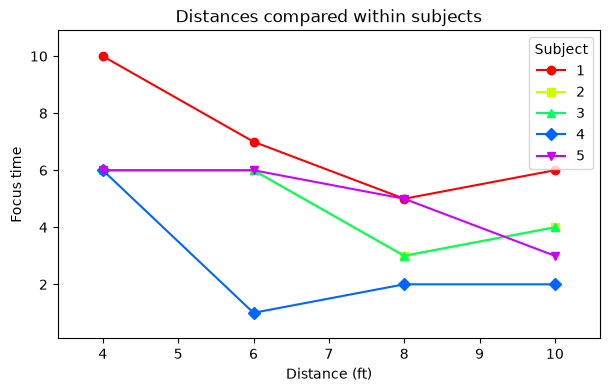

In [37]:
alpha = 0.05


def report_anova(model):
    """Balanced-design ANOVA, including an explicit decision for every model term."""
    table = sm.stats.anova_lm(model, typ=2)
    table["mean_sq"] = table["sum_sq"] / table["df"]
    display(table)
    for term, row in table.iloc[:-1].iterrows():
        print(f"{term}: F({row['df']:.0f}, {model.df_resid:.0f}) = {row['F']:.4f}, "
              f"p = {row['PR(>F)']:.6g}; "
              + ("reject H0" if row['PR(>F)'] < alpha else "do not reject H0"))
    return table


def residual_diagnostics(model, data, factors, title):
    """Check shape, spread and outliers; independence must come from the design."""
    residuals = model.resid
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(4 * (2 + len(factors)), 3.5))
    axes[0].scatter(model.fittedvalues, residuals)
    axes[0].axhline(0, color="red", ls="--")
    axes[0].set(xlabel="Fitted response", ylabel="Residual", title="Residuals vs fitted")
    sm.qqplot(residuals, line="s", ax=axes[1])
    axes[1].set_title("Normal Q-Q plot")
    for ax, factor in zip(axes[2:], factors):
        ax.scatter(data[factor], residuals)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=factor, ylabel="Residual", title=f"Residuals vs {factor}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    W, p_value = stats.shapiro(residuals)
    print(f"Shapiro-Wilk: H0 = normal errors; H1 = nonnormal errors. "
          f"W = {W:.4f}, p = {p_value:.6g}; "
          + ("reject H0" if p_value < alpha else "do not reject H0"))


focus_model = smf.ols("Time ~ C(Distance) + C(Subject)", data=focus).fit()
focus_anova = report_anova(focus_model)
display(focus.groupby("Distance")["Time"].agg(["mean", "std"]))
fig, ax = plt.subplots(figsize=(7, 4))
interaction_plot(focus["Distance"], focus["Subject"], focus["Time"], ax=ax,
                 markers=["o", "s", "^", "D", "v"])
ax.set(xlabel="Distance (ft)", ylabel="Focus time", title="Distances compared within subjects")
plt.show()

The RCBD model is $Y_{ij}=\mu+\tau_i+\beta_j+\varepsilon_{ij}$. `C(...)` treats the numeric labels as categories, so no linear relationship with distance is imposed. Each subject experiences every distance; the subject term removes between-person variation from the error.

For distance, $H_0$: all four distance means are equal; $H_1$: at least one differs. For subjects, $H_0$: all subject effects are zero; $H_1$: at least one differs. The ANOVA above reports both F statistics, p-values and decisions at 0.05. The additive model assumes independent, approximately normal errors of common variance and no distance-by-subject interaction.

**Result.** Distance affects mean focus time: $F(3,12)=8.6144$, $p=0.002543$. Subject differences are also detectable: $F(4,12)=7.1176$, $p=0.003548$. The estimated means at 4, 6, 8 and 10 ft are respectively 6.8, 5.2, 3.6 and 3.8; these suggest shorter focus time at the larger tested distances.

**Question 2.** Which distances differ? Use Tukey's HSD with the error mean square of the RCBD.

In [38]:
focus_tukey = tukey_from_model(focus_model, focus, "Distance", "Time", alpha=alpha)
display(focus_tukey)
print("Significant pairs:", focus_tukey.loc[focus_tukey["reject"], "pair"].tolist())

MS_E = 1.275, df_E = 12, n per level = 5, HSD = 2.12


,pair,diff,lower,upper,p_adj,reject
0,6 - 4,-1.6,-3.720219,0.520219,0.167524,False
1,8 - 4,-3.2,-5.320219,-1.079781,0.003616,True
2,10 - 4,-3.0,-5.120219,-0.879781,0.005837,True
3,8 - 6,-1.6,-3.720219,0.520219,0.167524,False
4,10 - 6,-1.4,-3.520219,0.720219,0.255437,False
5,10 - 8,0.2,-1.920219,2.320219,0.991929,False


Significant pairs: ['8 - 4', '10 - 4']


For every pair, $H_0$: the two distance means are equal; $H_1$: they differ. Tukey's HSD controls the familywise error at 0.05 over all six comparisons. It uses the **RCBD** residual mean square and residual degrees of freedom, with five observations per distance. `diff` means the second mean minus the first, and `lower`/`upper` form simultaneous 95% intervals. A rejected pair has an interval excluding zero.

**Result.** With $MS_E=1.275$, $df_E=12$ and HSD = 2.1202, only 4 versus 8 ft ($p_{adj}=0.003616$) and 4 versus 10 ft ($p_{adj}=0.005837$) differ significantly. Focus takes longer at 4 ft; the other four comparisons do not establish a difference.

**Question 3.** Analyse the residuals and perform Tukey's test for nonadditivity.

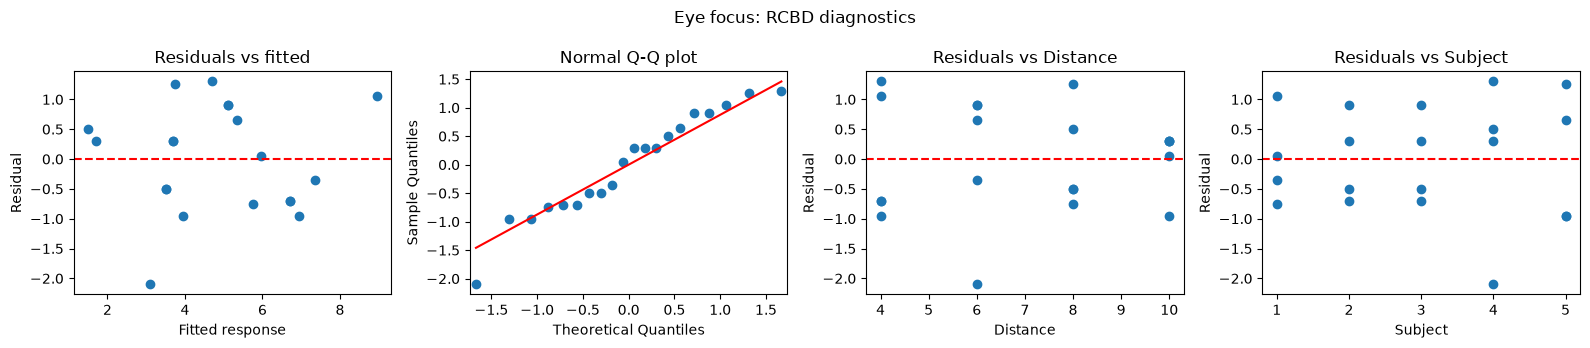

Shapiro-Wilk: H0 = normal errors; H1 = nonnormal errors. W = 0.9498, p = 0.363434; do not reject H0


,df,sum_sq,mean_sq,F,PR(>F)
C(Distance),3.0,32.950000,10.983333,8.041015,0.004078
C(Subject),4.0,36.300000,9.075000,6.643904,0.005688
q_nonadd,1.0,0.274947,0.274947,0.201292,0.662390
Residual,11.0,15.025053,1.365914,NaN,NaN


Nonadditivity: F(1, 11) = 0.2013, p = 0.66239; do not reject H0


In [39]:
residual_diagnostics(focus_model, focus, ["Distance", "Subject"], "Eye focus: RCBD diagnostics")
focus_nonadd = tukey_nonadditivity(focus, "Time", "Distance", "Subject")
display(focus_nonadd)
row = focus_nonadd.loc["q_nonadd"]
print(f"Nonadditivity: F(1, {focus_nonadd.loc['Residual', 'df']:.0f}) = {row['F']:.4f}, "
      f"p = {row['PR(>F)']:.6g}; "
      + ("reject H0" if row['PR(>F)'] < alpha else "do not reject H0"))

Tukey's nonadditivity test has $H_0:\gamma=0$ versus $H_1:\gamma\ne0$ in the extension $Y_{ij}=\mu+\tau_i+\beta_j+\gamma\tau_i\beta_j+\varepsilon_{ij}$. The helper forms the product of the estimated row and column effects and tests its extra sum of squares against the remaining residual error. This is a test of one particular multiplicative interaction; with one observation per cell, an unrestricted interaction cannot be separated from error. A nonsignificant result does not prove additivity. Shapiro-Wilk is an approximate supplementary check because fitted residuals are correlated; the plots and experimental design also matter.

**Diagnostics.** The residuals show no clear funnel or smooth trend. The 6-ft observation for subject 4 has the most negative residual, but the Q-Q plot is reasonably close to a line. Shapiro-Wilk gives $W=0.9498$, $p=0.3634$. The nonadditivity test gives $F(1,11)=0.2013$, $p=0.6624$, so it finds no evidence of this multiplicative departure from additivity. Independence relies on the randomized order within subjects; the table does not provide actual run order to check it.

**Question 4.** Reanalyse the data ignoring the subjects (completely randomized design) and compute the relative efficiency of the RCBD. Was blocking on subjects worthwhile?

In [40]:
focus_crd = smf.ols("Time ~ C(Distance)", data=focus).fit()
focus_crd_anova = report_anova(focus_crd)
variance_ratio, focus_R = relative_efficiency(focus_model, "C(Subject)", a=4, b=5)
print(f"MS_E (RCBD) = {focus_model.mse_resid:.6f}")
print(f"MS_E (CRD, subjects ignored) = {focus_crd.mse_resid:.6f}")
print(f"Observed CRD/RCBD error ratio = {focus_crd.mse_resid / focus_model.mse_resid:.4f}")
print(f"Estimated population variance ratio = {variance_ratio:.4f}; corrected efficiency R = {focus_R:.4f}")

,sum_sq,df,F,PR(>F),mean_sq
C(Distance),32.95,3.0,3.405685,0.043367,10.983333
Residual,51.60,16.0,NaN,NaN,3.225000


C(Distance): F(3, 16) = 3.4057, p = 0.0433665; reject H0
MS_E (RCBD) = 1.275000
MS_E (CRD, subjects ignored) = 3.225000
Observed CRD/RCBD error ratio = 2.5294
Estimated population variance ratio = 2.2879; corrected efficiency R = 2.2161


The CRD tests the same distance null hypothesis but leaves subject variation in the residuals. The direct ratio of the two fitted error mean squares and the textbook relative efficiency are different quantities: `relative_efficiency` estimates the variance for a hypothetical CRD, then applies the degrees-of-freedom correction given in the lecture. An efficiency above one means blocking is beneficial; it estimates how many times as many observations per distance a CRD would need for comparable precision.

**Result.** Ignoring subjects gives $MS_E=3.225$ instead of 1.275, and the distance test becomes $F(3,16)=3.4057$, $p=0.04337$. It still rejects at 0.05, but much less decisively. The observed error ratio is 2.5294 and the corrected relative efficiency is $R=2.2161$, so blocking was worthwhile.

**Question 5.** Assume that the subjects are a random sample of people. Estimate the block variance component $\hat\sigma^2_\beta = (MS_{Blocks} - MS_E)/a$.

In [41]:
a = focus["Distance"].nunique()
ms_subject = focus_anova.loc["C(Subject)", "mean_sq"]
focus_block_variance = (ms_subject - focus_model.mse_resid) / a
print(f"MS_Subject = {ms_subject:.6f}; MS_E = {focus_model.mse_resid:.6f}")
print(f"Estimated subject variance = {focus_block_variance:.6f}")
print(f"Estimated subject standard deviation = {np.sqrt(max(0, focus_block_variance)):.6f}")

MS_Subject = 9.075000; MS_E = 1.275000
Estimated subject variance = 1.950000
Estimated subject standard deviation = 1.396424


With randomly sampled subjects, $\beta_j$ is a random intercept with variance $\sigma_\beta^2$. Since $E(MS_{Subject})=\sigma^2+a\sigma_\beta^2$ and $E(MS_E)=\sigma^2$, their difference divided by the four distances is a method-of-moments variance estimate. The ANOVA subject test can now be read as $H_0:\sigma_\beta^2=0$ versus $H_1:\sigma_\beta^2>0$, under the random-block model.

**Conclusion for 4.21.** The subject variance estimate is $(9.075-1.275)/4=1.95$, with subject standard deviation about 1.396. Blocking improves precision substantially, and the clearest distance differences are the longer focus times at 4 ft compared with 8 and 10 ft.

### Problems 5.8, 5.23 and 5.36: breaking strength of a synthetic fibre

The factors that influence the breaking strength of a synthetic fibre are being studied. Four production machines and three
operators are chosen and a factorial experiment is run using fibre from the same production batch; two replicates.

In [42]:
fibre = pd.read_csv(URL + "Chapter5_Pr06.csv", sep=";")
display(fibre.pivot_table(index="Operator", columns="Machine", values="Strength", aggfunc=list))

Machine,1,2,3,4
Operator,,,,
1,"[109, 110]","[110, 115]","[108, 109]","[110, 108]"
2,"[110, 112]","[110, 111]","[111, 109]","[114, 112]"
3,"[116, 114]","[112, 115]","[114, 119]","[120, 117]"


**Question 1.** Draw an interaction plot, analyse the data and draw conclusions ($\alpha = 0.05$).

,sum_sq,df,F,PR(>F),mean_sq
C(Operator),160.333333,2.0,21.142857,0.000117,80.166667
C(Machine),12.458333,3.0,1.095238,0.388753,4.152778
C(Operator):C(Machine),44.666667,6.0,1.963370,0.150681,7.444444
Residual,45.500000,12.0,NaN,NaN,3.791667


C(Operator): F(2, 12) = 21.1429, p = 0.000116674; reject H0
C(Machine): F(3, 12) = 1.0952, p = 0.388753; do not reject H0
C(Operator):C(Machine): F(6, 12) = 1.9634, p = 0.150681; do not reject H0


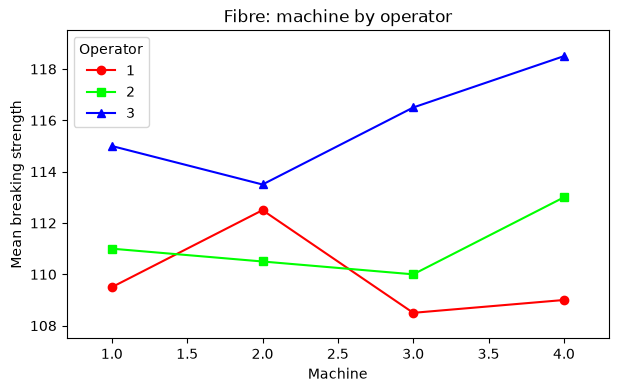

Operator
1    109.875
2    111.125
3    115.875
Name: Strength, dtype: float64

MS_E = 3.792, df_E = 12, n per level = 8, HSD = 2.597


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,1.25,-1.347459,3.847459,0.430209,False
1,3 - 1,6.00,3.402541,8.597459,0.000133,True
2,3 - 2,4.75,2.152541,7.347459,0.001021,True


In [43]:
fibre_model = smf.ols("Strength ~ C(Operator) * C(Machine)", data=fibre).fit()
fibre_anova = report_anova(fibre_model)
fig, ax = plt.subplots(figsize=(7, 4))
interaction_plot(fibre["Machine"], fibre["Operator"], fibre["Strength"], ax=ax,
                 markers=["o", "s", "^"])
ax.set(xlabel="Machine", ylabel="Mean breaking strength", title="Fibre: machine by operator")
plt.show()
display(fibre.groupby("Operator")["Strength"].mean())
display(tukey_from_model(fibre_model, fibre, "Operator", "Strength", alpha=alpha))

`C(Operator) * C(Machine)` expands to both main effects and their interaction. The interaction null is that all operator-by-machine interaction effects are zero; its alternative is that at least one is nonzero. Each main-effect null is equality of the marginal means of that factor, averaged equally over the other factor; its alternative is that at least one marginal mean differs. Both factors are treated as fixed, as in the lecture factorial examples.

The two observations per cell provide a pure-error estimate. The operator comparisons use Tukey's HSD with that full factorial error mean square, eight observations per operator, and familywise 0.05 error across the three pairs. Each pair tests equality against a two-sided difference; `p_adj` and `reject` give its adjusted p-value and decision.

**Result.** Operator is significant ($F(2,12)=21.1429$, $p=0.0001167$); machine ($p=0.3888$) and the interaction ($p=0.1507$) are not. Operator 3 has higher mean strength than operators 1 and 2 (Tukey adjusted $p=0.000133$ and 0.001021); operators 1 and 2 do not differ detectably ($p=0.4302$). This does not establish that machine effects or interaction are exactly zero.

**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

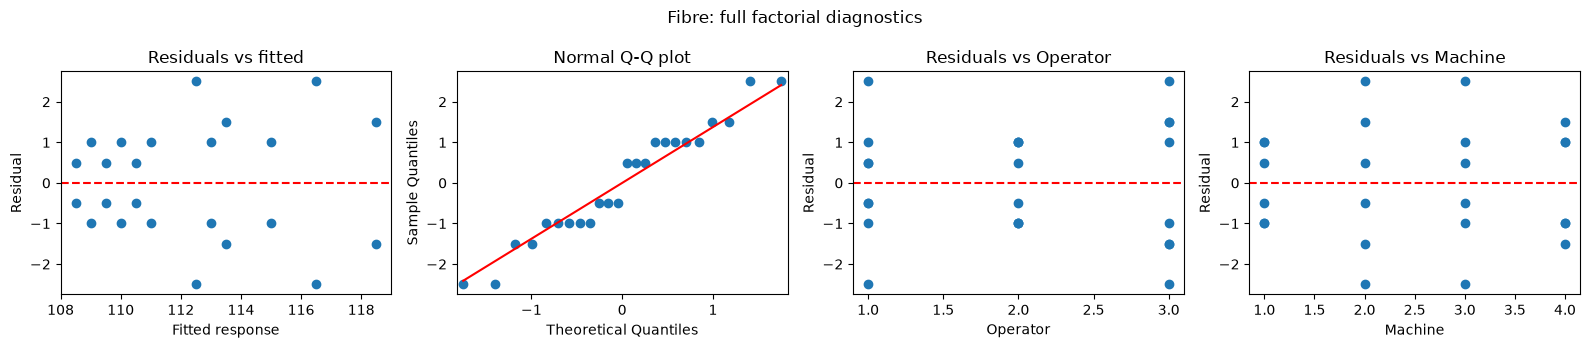

Shapiro-Wilk: H0 = normal errors; H1 = nonnormal errors. W = 0.9493, p = 0.261071; do not reject H0


In [44]:
residual_diagnostics(fibre_model, fibre, ["Operator", "Machine"], "Fibre: full factorial diagnostics")

The Q-Q plot is reasonably close to a line, with no clear trend or funnel in residuals versus fitted strength. Some cells have more spread than others, but two observations per cell give little information about individual cell variances. Shapiro-Wilk gives $W=0.9493$, $p=0.2611$, so it does not reject normality. The blocked model gives a similar diagnostic picture ($p=0.1708$). These are adequate working models for the exercise, provided randomization supports independence; run order is not available here.

**Question 3.** (Problems 5.23 and 5.36) Analyse the data assuming that the two replicates are blocks (the first observation in each cell
comes from the first replicate). Estimate the variance component for blocks, $\hat\sigma^2_{Block} = (MS_{Blocks} - MS_E)/(ab)$.
Does blocking change the conclusions?

,sum_sq,df,F,PR(>F),mean_sq
C(Block),2.041667,1.0,0.516779,0.487209,2.041667
C(Operator),160.333333,2.0,20.291467,0.000204,80.166667
C(Machine),12.458333,3.0,1.051135,0.408659,4.152778
C(Operator):C(Machine),44.666667,6.0,1.884308,0.171630,7.444444
Residual,43.458333,11.0,NaN,NaN,3.950758


C(Block): F(1, 11) = 0.5168, p = 0.487209; do not reject H0
C(Operator): F(2, 11) = 20.2915, p = 0.000203646; reject H0
C(Machine): F(3, 11) = 1.0511, p = 0.408659; do not reject H0
C(Operator):C(Machine): F(6, 11) = 1.8843, p = 0.17163; do not reject H0
MS_E unblocked = 3.791667; blocked = 3.950758
Block variance (method of moments) = -0.159091
Nonnegative variance estimate = 0.000000


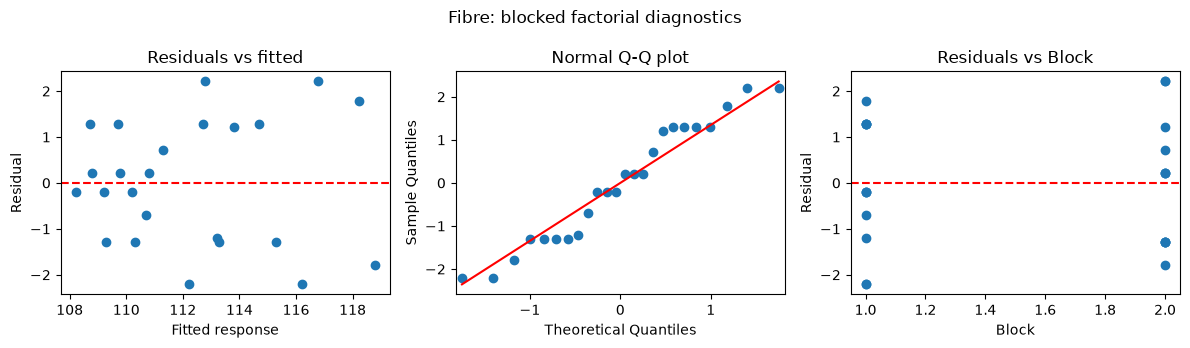

Shapiro-Wilk: H0 = normal errors; H1 = nonnormal errors. W = 0.9409, p = 0.170814; do not reject H0


In [45]:
# cumcount preserves the order within each operator-machine cell.
fibre["Block"] = fibre.groupby(["Operator", "Machine"]).cumcount() + 1
fibre_blocked = smf.ols("Strength ~ C(Block) + C(Operator) * C(Machine)", data=fibre).fit()
fibre_block_anova = report_anova(fibre_blocked)
ms_block = fibre_block_anova.loc["C(Block)", "mean_sq"]
fibre_block_variance = (ms_block - fibre_blocked.mse_resid) / 12
print(f"MS_E unblocked = {fibre_model.mse_resid:.6f}; blocked = {fibre_blocked.mse_resid:.6f}")
print(f"Block variance (method of moments) = {fibre_block_variance:.6f}")
print(f"Nonnegative variance estimate = {max(0, fibre_block_variance):.6f}")
residual_diagnostics(fibre_blocked, fibre, ["Block"], "Fibre: blocked factorial diagnostics")

Each block contains all $3\times4=12$ combinations. The added block term assumes a common shift across all combinations and no block-by-treatment interaction. The main-effect and interaction hypotheses remain as in Question 1. With random blocks, the block test is $H_0:\sigma^2_{Block}=0$ against $H_1:\sigma^2_{Block}>0$ (or equal block effects if blocks are fixed). The requested estimate is $(MS_{Block}-MS_E)/12$. A negative method-of-moments estimate is possible from sampling variation; report it, but interpret the nonnegative variance estimate as zero.

**Conclusion for 5.8/5.23/5.36.** The block test gives $F(1,11)=0.5168$, $p=0.4872$. Blocking increases $MS_E$ from 3.7917 to 3.9508 and gives a variance estimate of $-0.1591$ (zero after imposing nonnegativity), so these data show no benefit from blocking; operator remains the only significant treatment term.

### Problem 5.18: strength of paper (three factors)

The percentage of hardwood concentration in raw pulp (2, 4, 8 %), the vat pressure (400, 500, 650) and the cooking time of the
pulp (3.0, 4.0 hours) are being investigated for their effects on the strength of paper. A factorial experiment with two
replicates is conducted.

In [46]:
paper = pd.read_csv(URL + "Chapter5_Pr16.csv", sep=";")
display(paper.pivot_table(index=["Cooking_Time", "Hardwood"], columns="Pressure", values="Strength", aggfunc=list))

Pressure                          400             500             650
Cooking_Time Hardwood                                                
3            2         [196.6, 196.0]  [197.7, 196.0]  [199.8, 199.4]
             4         [198.5, 197.2]  [196.0, 196.9]  [198.4, 197.6]
             8         [197.5, 196.6]  [195.6, 196.2]  [197.4, 198.1]
4            2         [198.4, 198.6]  [199.6, 200.4]  [200.6, 200.9]
             4         [197.5, 198.1]  [198.7, 198.0]  [199.6, 199.0]
             8         [197.6, 198.4]  [197.0, 197.8]  [198.5, 199.8]

**Question 1.** Analyse the data and draw conclusions ($\alpha = 0.05$). Use plots of the main effects and of the important interactions.

,sum_sq,df,F,PR(>F),mean_sq
C(Hardwood),7.763889,2.0,10.619301,8.995614e-04,3.881944
C(Pressure),19.373889,2.0,26.499240,4.327241e-06,9.686944
C(Cooking_Time),20.250000,1.0,55.395137,6.745340e-07,20.250000
C(Hardwood):C(Pressure),6.091111,4.0,4.165653,1.462624e-02,1.522778
C(Hardwood):C(Cooking_Time),2.081667,2.0,2.847264,8.425969e-02,1.040833
C(Pressure):C(Cooking_Time),2.195000,2.0,3.002280,7.495643e-02,1.097500
C(Hardwood):C(Pressure):C(Cooking_Time),1.973333,4.0,1.349544,2.903053e-01,0.493333
Residual,6.580000,18.0,NaN,NaN,0.365556


C(Hardwood): F(2, 18) = 10.6193, p = 0.000899561; reject H0
C(Pressure): F(2, 18) = 26.4992, p = 4.32724e-06; reject H0
C(Cooking_Time): F(1, 18) = 55.3951, p = 6.74534e-07; reject H0
C(Hardwood):C(Pressure): F(4, 18) = 4.1657, p = 0.0146262; reject H0
C(Hardwood):C(Cooking_Time): F(2, 18) = 2.8473, p = 0.0842597; do not reject H0
C(Pressure):C(Cooking_Time): F(2, 18) = 3.0023, p = 0.0749564; do not reject H0
C(Hardwood):C(Pressure):C(Cooking_Time): F(4, 18) = 1.3495, p = 0.290305; do not reject H0


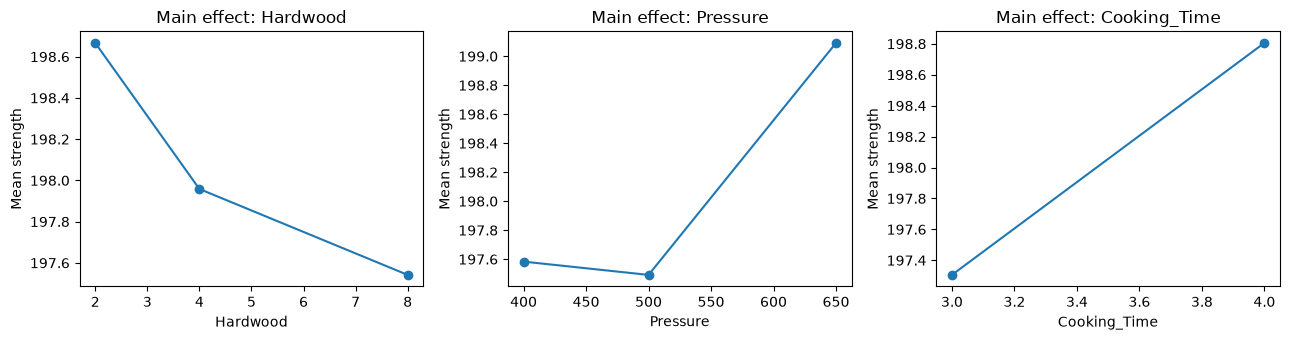

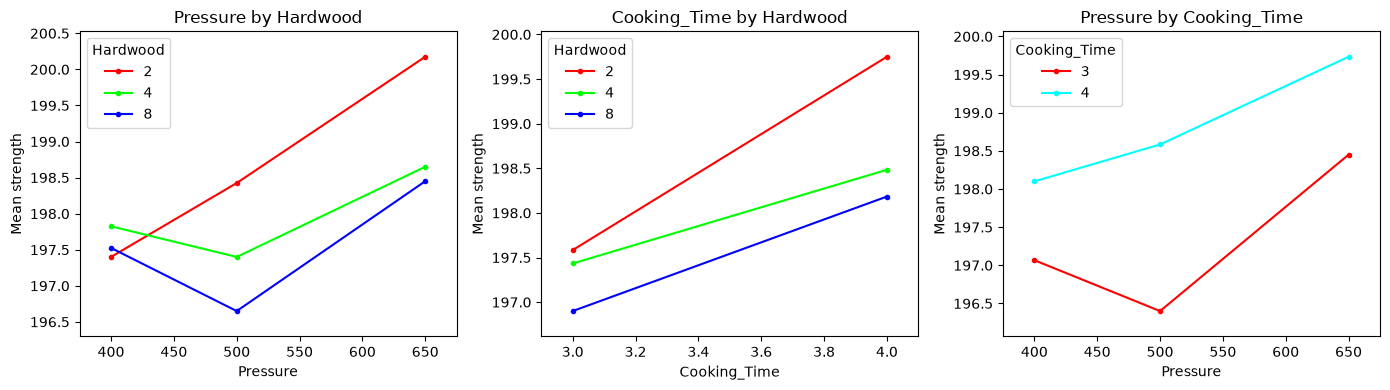

In [47]:
paper_model = smf.ols("Strength ~ C(Hardwood) * C(Pressure) * C(Cooking_Time)", data=paper).fit()
paper_anova = report_anova(paper_model)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, factor in zip(axes, ["Hardwood", "Pressure", "Cooking_Time"]):
    paper.groupby(factor)["Strength"].mean().plot(marker="o", ax=ax)
    ax.set(xlabel=factor, ylabel="Mean strength", title=f"Main effect: {factor}")
plt.tight_layout()
plt.show()
# Show every two-factor interaction, so the significant ones have context.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, x, trace in zip(axes, ["Pressure", "Cooking_Time", "Pressure"],
                        ["Hardwood", "Hardwood", "Cooking_Time"]):
    interaction_plot(paper[x], paper[trace], paper["Strength"], ax=ax)
    ax.set(xlabel=x, ylabel="Mean strength", title=f"{x} by {trace}")
plt.tight_layout()
plt.show()

The full three-factor model includes all main effects, all three two-factor interactions and the three-factor interaction, leaving 18 pure-error degrees of freedom. For each main effect, $H_0$ is equality of its marginal means; $H_1$ is at least one difference. For each two-factor term, $H_0$ is no interaction averaged over the third factor; $H_1$ is a nonzero interaction. For the three-factor term, $H_0$ is that the two-factor interaction does not depend on the third factor; $H_1$ is that it does. The output states the F statistic, p-value and decision for each term. The balanced design makes the factor terms orthogonal. Retain the full model and its pure-error estimate, rather than removing terms after observing their p-values.

**Result.** Hardwood, pressure and cooking time all have significant main effects (respectively $p=0.0008996$, $4.327\times10^{-6}$ and $6.745\times10^{-7}$). Hardwood-by-pressure is significant ($F(4,18)=4.1657$, $p=0.01463$); the other two-factor interactions and the three-factor interaction are not significant at 0.05. Interpret hardwood and pressure together: the strength gain from changing pressure depends on hardwood concentration. Longer cooking has the higher marginal mean over the tested settings.

**Question 2.** Prepare appropriate residual plots and comment on the model's adequacy.

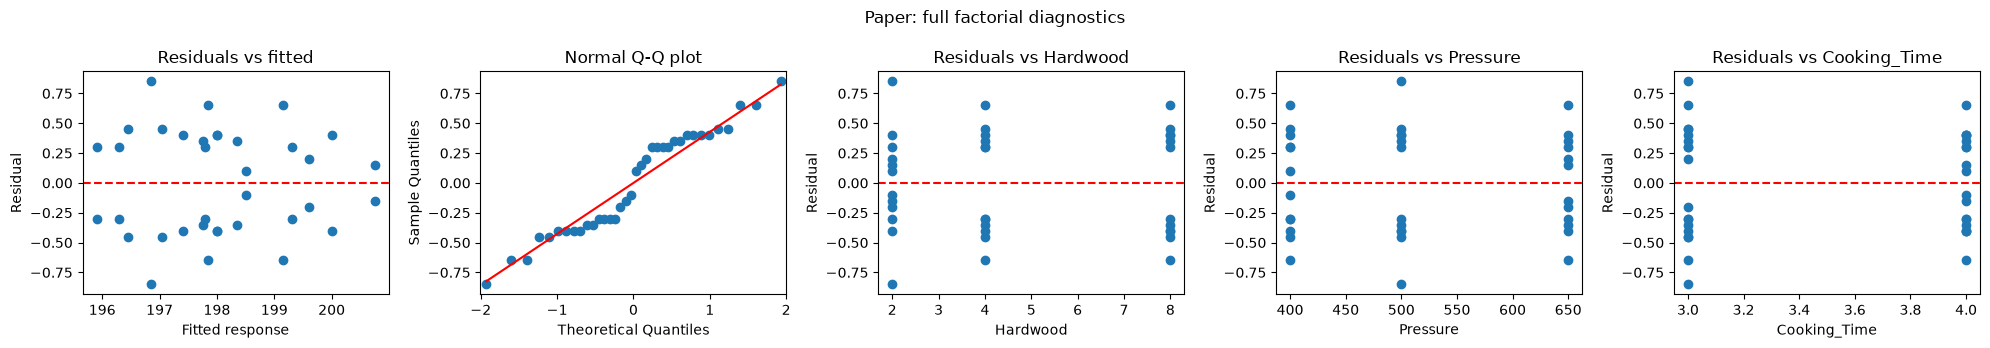

Shapiro-Wilk: H0 = normal errors; H1 = nonnormal errors. W = 0.9390, p = 0.0471666; reject H0


In [48]:
residual_diagnostics(paper_model, paper, ["Hardwood", "Pressure", "Cooking_Time"],
                     "Paper: full factorial diagnostics")

There is no clear smooth trend or strong funnel in the residual plot, but the Q-Q plot shows a gap around zero and a departure from a straight line. With two replicates per cell, residuals necessarily appear in opposite pairs; individual cell variances cannot be judged reliably. Shapiro-Wilk gives $W=0.9390$, $p=0.04717$, a borderline rejection at 0.05, so exact normality is questionable. Retain the requested conventional ANOVA while treating its p-values and confidence intervals as conditional on the error assumptions; more replication is desirable. The plots cannot verify independence without run order.

**Question 3.** Under what set of conditions would you operate this process? Why?

In [49]:
paper_cells = paper.groupby(["Hardwood", "Pressure", "Cooking_Time"])["Strength"].agg(["mean", "count"])
paper_cells = paper_cells.sort_values("mean", ascending=False)
# Individual intervals describe estimation uncertainty, not simultaneous ranking confidence.
paper_halfwidth = stats.t.ppf(0.975, paper_model.df_resid) * np.sqrt(paper_model.mse_resid / paper_cells["count"])
paper_cells["CI_lower"] = paper_cells["mean"] - paper_halfwidth
paper_cells["CI_upper"] = paper_cells["mean"] + paper_halfwidth
display(paper_cells)
print("Largest observed cell mean (Hardwood, Pressure, Cooking_Time):", paper_cells.index[0])

mean  count    CI_lower    CI_upper
Hardwood Pressure Cooking_Time                                       
2        650      4             200.75      2  199.851803  201.648197
         500      4             200.00      2  199.101803  200.898197
         650      3             199.60      2  198.701803  200.498197
4        650      4             199.30      2  198.401803  200.198197
8        650      4             199.15      2  198.251803  200.048197
2        400      4             198.50      2  197.601803  199.398197
4        500      4             198.35      2  197.451803  199.248197
         650      3             198.00      2  197.101803  198.898197
8        400      4             198.00      2  197.101803  198.898197
4        400      3             197.85      2  196.951803  198.748197
                  4             197.80      2  196.901803  198.698197
8        650      3             197.75      2  196.851803  198.648197
         500      4             197.40      2  196.501803  198.298197
         400      3             197.05      2  196.151803  197.948197
2        500      3             196.85      2  195.951803  197.748197
4        500      3             196.45      2  195.551803  197.348197
2        400      3             196.30      2  195.401803  197.198197
8        500      3             195.90      2  195.001803  196.798197

Largest observed cell mean (Hardwood, Pressure, Cooking_Time): (np.int64(2), np.int64(650), np.int64(4))


Choose among the measured combinations using their cell means, because interactions can make a combination differ from what separate main effects suggest. The intervals use $\bar y_{ijk}\pm t_{0.975,18}\sqrt{MS_E/2}$. These are individual 95% confidence intervals, not simultaneous intervals and not proof that the selected maximum is better than every alternative. The recommendation assumes the objective is maximum strength, with no cost or operating constraints, and makes no claim about untested settings.

**Conclusion for 5.18.** For maximum strength among the tested settings, choose 2% hardwood, pressure 650 and cooking time 4 hours: the estimated mean is 200.75, with an individual 95% interval [199.852, 201.648]. This is a provisional recommendation from two replicates per cell; confirm it with additional runs, especially because the residual diagnostics question exact normality.

### Problem 5.20: number of replicates (data of Problem 5.3)

The yield of a chemical process is studied at three pressures (200, 215, 230 psig) and three temperatures (150, 160, 170 $^\circ$C),
with two replicates (Problem 5.3).

In [50]:
yield_ = pd.read_csv(URL + "Chapter5_Pr01.csv", sep=";")
display(yield_.pivot_table(index="Temperature", columns="Pressure", values="Yield", aggfunc=list))

Pressure,200,215,230
Temperature,,,
150,"[90.4, 90.2]","[90.7, 90.6]","[90.2, 90.4]"
160,"[90.1, 90.3]","[90.5, 90.6]","[89.9, 90.1]"
170,"[90.5, 90.7]","[90.8, 90.9]","[90.1, 90.4]"


**Question 1.** (Problem 5.3) Analyse the data and draw conclusions ($\alpha = 0.05$).

,sum_sq,df,F,PR(>F),mean_sq
C(Pressure),0.767778,2.0,21.59375,0.000367,0.383889
C(Temperature),0.301111,2.0,8.46875,0.008539,0.150556
C(Pressure):C(Temperature),0.068889,4.0,0.96875,0.470006,0.017222
Residual,0.160000,9.0,NaN,NaN,0.017778


C(Pressure): F(2, 9) = 21.5938, p = 0.000367318; reject H0
C(Temperature): F(2, 9) = 8.4688, p = 0.00853915; reject H0
C(Pressure):C(Temperature): F(4, 9) = 0.9688, p = 0.470006; do not reject H0


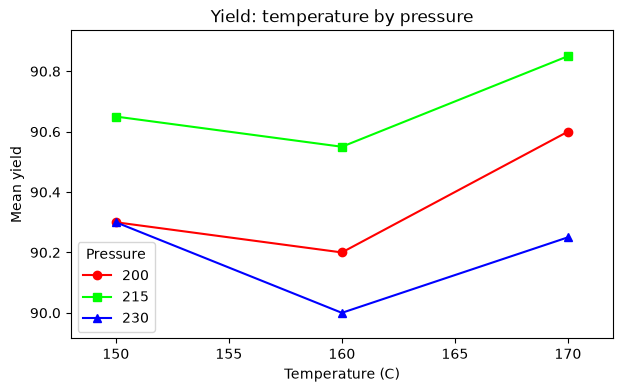

Pressure
200    90.366667
215    90.683333
230    90.183333
Name: Yield, dtype: float64

Temperature
150    90.416667
160    90.250000
170    90.566667
Name: Yield, dtype: float64

MS_E = 0.01778, df_E = 9, n per level = 6, HSD = 0.2149


,pair,diff,lower,upper,p_adj,reject
0,215 - 200,0.316667,0.101738,0.531595,0.006652,True
1,230 - 200,-0.183333,-0.398262,0.031595,0.094491,False
2,230 - 215,-0.500000,-0.714929,-0.285071,0.000295,True


MS_E = 0.01778, df_E = 9, n per level = 6, HSD = 0.2149


,pair,diff,lower,upper,p_adj,reject
0,160 - 150,-0.166667,-0.381595,0.048262,0.131315,False
1,170 - 150,0.150000,-0.064929,0.364929,0.180908,False
2,170 - 160,0.316667,0.101738,0.531595,0.006652,True


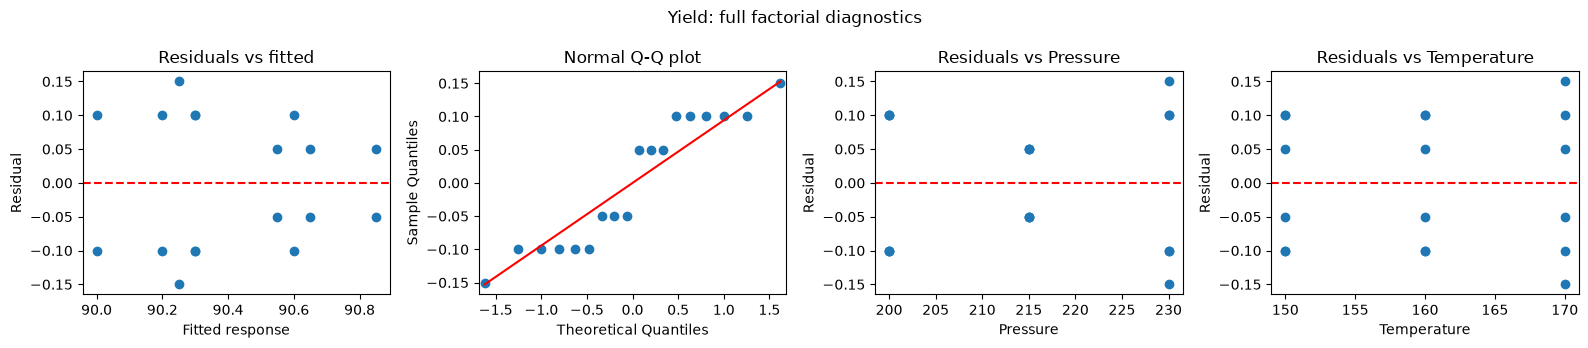

Shapiro-Wilk: H0 = normal errors; H1 = nonnormal errors. W = 0.8737, p = 0.0204567; reject H0


In [51]:
yield_model = smf.ols("Yield ~ C(Pressure) * C(Temperature)", data=yield_).fit()
yield_anova = report_anova(yield_model)
fig, ax = plt.subplots(figsize=(7, 4))
interaction_plot(yield_["Temperature"], yield_["Pressure"], yield_["Yield"], ax=ax,
                 markers=["o", "s", "^"])
ax.set(xlabel="Temperature (C)", ylabel="Mean yield", title="Yield: temperature by pressure")
plt.show()
display(yield_.groupby("Pressure")["Yield"].mean())
display(yield_.groupby("Temperature")["Yield"].mean())
display(tukey_from_model(yield_model, yield_, "Pressure", "Yield", alpha=alpha))
display(tukey_from_model(yield_model, yield_, "Temperature", "Yield", alpha=alpha))
residual_diagnostics(yield_model, yield_, ["Pressure", "Temperature"], "Yield: full factorial diagnostics")

The pressure and temperature null hypotheses are equality of their respective marginal means; each alternative is at least one difference. The interaction null is that all pressure-by-temperature interaction effects are zero; its alternative is a nonzero interaction. Both factors are categorical here. Tukey comparisons use the full factorial residual mean square and 9 error degrees of freedom, with six observations per marginal mean. Each factor is a separate family of three two-sided pairwise tests, with familywise error controlled at 0.05 within that family.

**Result.** Pressure ($F(2,9)=21.5938$, $p=0.0003673$) and temperature ($F(2,9)=8.4688$, $p=0.008539$) are significant; their interaction is not ($F(4,9)=0.9688$, $p=0.4700$). The full-model $MS_E$ is 0.0177778. Tukey finds pressure 215 higher than both 200 and 230, and temperature 170 higher than 160; the other pairs are not significant within their respective families.

**Diagnostics.** Residuals have no clear trend, but only a few distinct magnitudes. They occur in opposite pairs because the fitted full model reproduces each two-observation cell mean. The rounded observations and tiny within-cell sample size limit diagnosis; Shapiro-Wilk gives $W=0.8737$, $p=0.02046$, so normality should not simply be assumed verified. The conventional ANOVA and subsequent F-based power calculations are conditional on the normal, common-variance error model; additional replicates would help assess it.

**Question 2.** (Problem 5.20) We wish to reject the null hypothesis with a high probability if the difference in the true mean
yield at any two pressures is as great as 0.5. If a reasonable prior estimate of the standard deviation of yield is 0.1,
how many replicates should be run? Compute the power for $n = 2, 3, 4$ with `anova_power()`.

In [52]:
def pressure_power_table(D, sigma, ns):
    """Least-favourable omnibus pressure F-test power, with three temperatures."""
    a = yield_["Pressure"].nunique()
    b = yield_["Temperature"].nunique()
    rows = []
    for n in ns:
        lam = n * b * D**2 / (2 * sigma**2)
        df1, df2 = a - 1, a * b * (n - 1)
        rows.append({"n per cell": n, "total runs": a*b*n, "lambda": lam,
                     "df1": df1, "df2": df2, "power": anova_power(lam, df1, df2, alpha)})
    return pd.DataFrame(rows)


prior_power = pressure_power_table(D=0.5, sigma=0.1, ns=[2, 3, 4])
display(prior_power)
print("Minimum replicated n for at least 90% power:",
      int(prior_power.loc[prior_power["power"] >= 0.90, "n per cell"].iloc[0]))

,n per cell,total runs,lambda,df1,df2,power
0,2,18,75.0,2,9,0.999999
1,3,27,112.5,2,18,1.000000
2,4,36,150.0,2,27,1.000000


Minimum replicated n for at least 90% power: 2


The target is power of the **omnibus pressure F-test**, not of each Tukey comparison. Its $H_0$ is equality of the three pressure means; the planning alternative has a maximum mean difference of at least $D$. For a fixed range $D$, the least favourable arrangement puts the two extremes $D$ apart and the remaining mean at the midpoint. Thus $\sum_i(\mu_i-\bar\mu)^2=D^2/2$ and $\lambda=nbD^2/(2\sigma^2)$, with $a=b=3$, numerator df $a-1=2$ and denominator df $ab(n-1)$.

`anova_power` integrates the noncentral F tail above the central F critical value at 0.05. “High probability” is unspecified, so use **90%** as the planning target and also show the actual powers. Here $n$ is replicates per pressure-temperature cell, giving $9n$ total runs; the search starts at two replicates so the full interaction model has an error estimate. This is prospective planning, not a new test on the observed data.

**Result.** With $D=0.5$ and $\sigma=0.1$, the powers for $n=2,3,4$ are approximately 0.999999, 1.000000 and 1.000000. Two replicates per cell (18 total runs) already exceed 90% and 95% power under these assumptions.

**Question 3.** Repeat Question 2 with $\sigma$ estimated from the data of Problem 5.3 ($\hat\sigma = \sqrt{MS_E}$) and with a difference of 0.25. How sensitive is the required $n$ to these inputs?

In [53]:
sigma_data = np.sqrt(yield_model.mse_resid)
print(f"Estimated sigma from full factorial pure error = {sigma_data:.6f}")
observed_power = pressure_power_table(D=0.25, sigma=sigma_data, ns=[2, 3, 4])
display(observed_power)
# Extend the search because n=2,3,4 need not attain the requested target.
planning_grid = pressure_power_table(D=0.25, sigma=sigma_data, ns=range(2, 101))
for target in [0.80, 0.90, 0.95]:
    chosen = planning_grid.loc[planning_grid["power"] >= target].iloc[0]
    print(f"Target {target:.0%}: n = {int(chosen['n per cell'])}, "
          f"total runs = {int(chosen['total runs'])}, power = {chosen['power']:.6f}")
# Separate the effects of changing D and sigma.
for D, sigma in [(0.5, 0.1), (0.25, 0.1), (0.5, sigma_data), (0.25, sigma_data)]:
    grid = pressure_power_table(D, sigma, range(2, 101))
    chosen = grid.loc[grid["power"] >= 0.90].iloc[0]
    print(f"D={D:.2f}, sigma={sigma:.6f}: minimum n for 90% = {int(chosen['n per cell'])}")

Estimated sigma from full factorial pure error = 0.133333


,n per cell,total runs,lambda,df1,df2,power
0,2,18,10.546875,2,9,0.684922
1,3,27,15.820312,2,18,0.914541
2,4,36,21.093750,2,27,0.979431


Target 80%: n = 3, total runs = 27, power = 0.914541
Target 90%: n = 3, total runs = 27, power = 0.914541
Target 95%: n = 4, total runs = 36, power = 0.979431
D=0.50, sigma=0.100000: minimum n for 90% = 2
D=0.25, sigma=0.100000: minimum n for 90% = 2
D=0.50, sigma=0.133333: minimum n for 90% = 2
D=0.25, sigma=0.133333: minimum n for 90% = 3


At fixed $n$, noncentrality scales as $(D/\sigma)^2$: halving $D$ divides it by four, while increasing $\sigma$ reduces power further. Holding power roughly fixed therefore requires $n$ proportional to $\sigma^2/D^2$, with an additional change because the error degrees of freedom grow with $n$. The estimate of $\sigma$ uses only nine error degrees of freedom, so this plug-in sample-size calculation has uncertainty; it should not be treated as a guaranteed power level.

**Conclusion for 5.20.** Using $\hat\sigma=0.133333$ and $D=0.25$, power is 0.684922, 0.914541 and 0.979431 for $n=2,3,4$. Three replicates per cell (27 runs) reach 90% power; four (36 runs) reach 95%. The smaller target difference together with the larger error estimate changes the 90% recommendation from two to three replicates.